# Алмазов МРТ v3 — обнаружение и локализация (сегментация) опухолей мозга
**Как запускать:** Среда выполнения → Сменить среду → **T4 GPU**, затем **Среда выполнения → Выполнить все**.
Всё важное сохраняется в Google Drive (`MyDrive/almazov`). Если Colab оборвался — снова «Выполнить все»: данные, разбиение и обученные эпохи подхватятся.

Шаги: 0 настройка · 1 данные · 2 Figshare (маски, ID пациентов) · 3 предобработка и аудит · 4 примеры утечек · 5 честное разбиение · 6–7 классификатор · 8–9 сегментация · 10 сравнение с «наивной» оценкой · 11 итоги · 12 демо для врача.

In [16]:
# === 0. НАСТРОЙКА ===
!nvidia-smi -L
!pip -q install timm segmentation-models-pytorch h5py gradio
from google.colab import drive
drive.mount('/content/drive')
import os, json, time, re, random, hashlib, glob, zipfile, shutil
from pathlib import Path
import numpy as np, pandas as pd, cv2, torch, torch.nn as nn
import matplotlib.pyplot as plt
cv2.setNumThreads(0)
W = Path('/content/drive/MyDrive/almazov'); W.mkdir(parents=True, exist_ok=True)
(W/'figs').mkdir(exist_ok=True); (W/'ckpt').mkdir(exist_ok=True)
ORG = Path('/content/org'); FIG = Path('/content/fig')
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
assert dev == 'cuda', 'Нет GPU: Среда выполнения -> Сменить среду -> T4 GPU'
CLASSES = ['Глиома', 'Менингиома', 'Гипофиз', 'Опухоли нет']   # индекс 3 = нет опухоли
print('OK, папка результатов:', W)

GPU 0: Tesla T4 (UUID: GPU-8a93e6f5-6417-4bbd-e8a1-38d4fc5949a7)
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OK, папка результатов: /content/drive/MyDrive/almazov


In [30]:
# === 1. ДАННЫЕ ОРГАНИЗАТОРОВ: распаковка Almazov_MRI.zip из Google Drive ===
# Набор зафиксирован: 9150 из 12064 файлов (остальные источник не отдал). Пропуски распределены по всем классам.
def n_imgs(root): return sum(1 for p in Path(root).rglob('*') if p.suffix.lower() in ('.jpg', '.jpeg', '.png'))
if not ORG.exists() or n_imgs(ORG) < 9000:
    zs = sorted(glob.glob('/content/drive/MyDrive/**/Almazov_MRI*.zip', recursive=True))
    assert zs, 'Не нашёл Almazov_MRI.zip в Google Drive'
    z = zipfile.ZipFile(zs[0]); cnt = 0
    for info in z.infolist():
        name = info.filename
        if not (info.flag_bits & 0x800):          # zip из Windows без UTF-8: чиним кириллицу
            try: name = name.encode('cp437').decode('cp866')
            except Exception: pass
        parts = name.replace('\\', '/').split('/')
        if parts and parts[0].startswith('Almazov_MRI'): parts = parts[1:]
        if info.is_dir() or not parts or not parts[-1].lower().endswith(('.jpg', '.jpeg', '.png')): continue
        dst = ORG.joinpath(*parts); dst.parent.mkdir(parents=True, exist_ok=True)
        with z.open(info) as s, open(dst, 'wb') as d: shutil.copyfileobj(s, d)
        cnt += 1
    print('Распаковано из', zs[0], ':', cnt)
print('Снимков локально:', n_imgs(ORG))

Снимков локально: 9150
Снимков локально: 9150


In [36]:
# === 2. FIGSHARE (Cheng): 3064 снимка T1+контраст, маски опухолей от радиологов, ID пациентов ===
import h5py
FIGNPZ = W/'figshare256.npz'
if not FIGNPZ.exists():
    FIG.mkdir(exist_ok=True)
    for fid in [3381290, 3381293, 3381296, 3381302]:
        z = FIG/f'{fid}.zip'
        if not z.exists():
            !wget -q -O "{z}" https://ndownloader.figshare.com/files/{fid}
        zipfile.ZipFile(z).extractall(FIG/'mat')
    files = sorted(glob.glob(str(FIG/'mat'/'**'/'*.mat'), recursive=True), key=lambda s: int(Path(s).stem))
    X, M, Y, P, IDX = [], [], [], [], []
    for f in files:
        with h5py.File(f, 'r') as h:
            cj = h['cjdata']
            img = np.array(cj['image']).T.astype(np.float32)
            msk = np.array(cj['tumorMask']).T.astype(np.uint8)
            lab = int(np.array(cj['label']).flatten()[0])
            pid = ''.join(chr(int(c)) for c in np.array(cj['PID']).flatten())
        lo, hi = np.percentile(img, 0.5), np.percentile(img, 99.5)
        img = np.clip((img-lo)/(hi-lo+1e-6), 0, 1)*255
        X.append(cv2.resize(img.astype(np.uint8), (256, 256), interpolation=cv2.INTER_AREA))
        M.append(cv2.resize(msk, (256, 256), interpolation=cv2.INTER_NEAREST))
        Y.append(lab); P.append(pid); IDX.append(int(Path(f).stem))
    cheng2ours = {1: 1, 2: 0, 3: 2}     # Cheng: 1 менингиома, 2 глиома, 3 гипофиз
    np.savez_compressed(FIGNPZ, X=np.stack(X), M=np.stack(M), y=np.array([cheng2ours[v] for v in Y]),
                        pid=np.array(P), idx=np.array(IDX))
F = np.load(FIGNPZ)
fX, fM, fy, fpid = F['X'], F['M'], F['y'], F['pid'].astype(str)
print('Figshare:', fX.shape, 'пациентов:', len(set(fpid)), 'по классам:', np.bincount(fy))

Figshare: (3064, 256, 256) пациентов: 233 по классам: [1426  708  930]


In [37]:
# === 3. ПРЕДОБРАБОТКА + АУДИТ ДАННЫХ (дубли, аугментированные копии, общие пациенты с Figshare) ===
from PIL import Image
def prep(g):
    # единая предобработка для любых источников: серый -> квадрат с чёрными полями -> 256x256 -> контраст по перцентилям
    h, w = g.shape; s = max(h, w)
    if h != w:
        c = np.zeros((s, s), g.dtype); c[(s-h)//2:(s-h)//2+h, (s-w)//2:(s-w)//2+w] = g; g = c
    g = cv2.resize(g, (256, 256), interpolation=cv2.INTER_AREA if s > 256 else cv2.INTER_LINEAR).astype(np.float32)
    lo, hi = np.percentile(g, 0.5), np.percentile(g, 99.5)
    return (np.clip((g - lo) / (hi - lo + 1e-6), 0, 1) * 255).astype(np.uint8)

files = sorted(p for p in ORG.rglob('*') if p.suffix.lower() in ('.jpg', '.jpeg', '.png'))
rows, imgs = [], []
for p in files:
    parts = [s.strip() for s in p.relative_to(ORG).parts]
    split = 'test' if any(s.startswith('Тест') for s in parts) else 'train'
    lab = next(s for s in parts if s in CLASSES)
    g = np.array(Image.open(p).convert('L'))
    imgs.append(prep(g))
    rows.append(dict(path=str(p), name=p.name, split=split, label=CLASSES.index(lab), h=g.shape[0], w=g.shape[1],
                     pix=hashlib.sha1(g.tobytes()).hexdigest()))
df = pd.DataFrame(rows); A = np.stack(imgs); n = len(df); LAB = df.label.values
def source(nm):
    if re.match(r'^T[re]-', nm): return 'Kaggle Tr/Te'
    if re.search(r'_(HF|VF|RO|BR|SP|DA)_\.', nm): return 'аугм. копии'
    if re.match(r'^[PGMN]_\d+\.', nm): return 'P/G/M/N_n'
    if re.match(r'^\d+\.', nm): return 'числовые'
    if re.match(r'^(gg|m|p|image)', nm, re.I): return 'SARTAJ-подобные'
    return 'Br35H/прочие'
df['source'] = df.name.map(source)
df['augbase'] = df.name.str.extract(r'^([PGMN]_\d+)(?:_[A-Z]{2}_)?\.', expand=False)
print(df.groupby(['split', 'label']).size().unstack().rename(columns=dict(enumerate(CLASSES))))
print(pd.crosstab(df.source, df.split))

# --- похожесть снимков: корреляция 64x64 с учётом 8 поворотов/отражений ---
def small(arr, s=64): return np.stack([cv2.resize(a, (s, s), interpolation=cv2.INTER_AREA) for a in arr]).astype(np.float32)
def zt(x):
    x = x.reshape(len(x), -1); x = x - x.mean(1, keepdim=True); return x / (x.norm(dim=1, keepdim=True) + 1e-6)
def d8_t(x, t):
    y = torch.rot90(x, t // 2, (1, 2)); return torch.flip(y, (2,)) if t % 2 else y
S64 = torch.tensor(small(A)); Z = zt(S64).to(dev); ZD = [zt(d8_t(S64, t)).to(dev) for t in range(8)]
I, J, C = [], [], []
for s in range(0, n, 512):
    e = min(n, s + 512)
    best = torch.stack([ZD[t][s:e] @ Z.T for t in range(8)]).max(0).values
    best[torch.arange(e - s, device=dev), torch.arange(s, e, device=dev)] = 0
    ii, jj = torch.nonzero(best >= 0.97, as_tuple=True)
    keep = (ii + s) < jj
    I.append((ii[keep] + s).cpu().numpy()); J.append(jj[keep].cpu().numpy()); C.append(best[ii[keep], jj[keep]].cpu().numpy())
I, J, C = np.concatenate(I), np.concatenate(J), np.concatenate(C)
FZt = zt(torch.tensor(small(fX))).to(dev)
fbest = np.zeros(n, np.float32); farg = np.zeros(n, int)
for s in range(0, n, 512):
    e = min(n, s + 512)
    c = torch.stack([ZD[t][s:e] @ FZt.T for t in range(8)]).max(0).values
    v, a = c.max(1); fbest[s:e] = v.cpu().numpy(); farg[s:e] = a.cpu().numpy()
fig_ok = (LAB != 3) & (fy[farg] == LAB)
del Z, ZD, FZt; torch.cuda.empty_cache()

def build(thr_dup, thr_fig, use_pid, use_names):
    par = list(range(n))
    def find(a):
        while par[a] != a:
            par[a] = par[par[a]]; a = par[a]
        return a
    def un(a, b):
        a, b = find(a), find(b)
        if a != b: par[a] = b
    for ids in df.groupby('pix').groups.values():
        ids = list(ids)
        for i in ids[1:]: un(ids[0], i)
    if use_names:
        for ids in df.dropna(subset=['augbase']).groupby(['augbase', 'label']).groups.values():
            ids = list(ids)
            for i in ids[1:]: un(ids[0], i)
    m = (C >= thr_dup) & (LAB[I] == LAB[J])
    for i, j in zip(I[m].tolist(), J[m].tolist()): un(i, j)
    pid = np.where((fbest >= thr_fig) & fig_ok, fpid[farg], '')
    if use_pid:
        first = {}
        for i in np.where(pid != '')[0].tolist():
            if pid[i] in first: un(first[pid[i]], i)
            else: first[pid[i]] = i
    return np.array([find(i) for i in range(n)]), pid

te = (df.split == 'test').values
def leak(g):
    trg = set(g[~te]); return te & np.isin(g, list(trg))
print('\nЧувствительность к порогу похожести:')
for thr in (0.97, 0.98, 0.99):
    gi, _ = build(thr, thr, False, False); gs, _ = build(thr, thr, True, False)
    print(f'  порог {thr}: тест-снимков с копией в обучении {leak(gi).sum()}/{te.sum()},'
          f' с копией или тем же пациентом {leak(gs).sum()}/{te.sum()}')
THR = 0.98
df['group'], pid = build(THR, THR, True, True)       # для разбиения: самый осторожный вариант
df['imgcomp'], _ = build(THR, THR, False, False)     # «тот же снимок» (копия, отражение, ресайз)
gstat, _ = build(THR, THR, True, False)
df['pid'] = pid; df['fig_i'] = np.where(pid != '', farg, -1)
df['leak_copy'] = leak(df.imgcomp.values); df['leak_patient'] = leak(gstat)
df['label_conflict'] = df.group.map(df.groupby('group').label.nunique() > 1).values
audit = dict(files=n, groups=int(df.group.nunique()), biggest_group=int(df.group.value_counts().max()),
             exact_dup_groups=int((df.groupby('pix').size() > 1).sum()),
             org_images_matched_to_figshare=int((pid != '').sum()), figshare_patients_found=len(set(pid) - {''}),
             test_images=int(te.sum()), test_with_copy_in_train=int(df.leak_copy.sum()),
             test_with_copy_or_same_patient_in_train=int(df.leak_patient.sum()),
             label_conflict_images=int(df.label_conflict.sum()))
print(json.dumps(audit, ensure_ascii=False, indent=1))
print(df[te].groupby('label')[['leak_copy', 'leak_patient']].mean().rename(index=dict(enumerate(CLASSES))).round(3))
json.dump(audit, open(W/'audit_v3.json', 'w'), ensure_ascii=False, indent=1)

label  Глиома  Менингиома  Гипофиз  Опухоли нет
split                                          
test      582         413      488          388
train    2265        1648     1909         1457
split            test  train
source                      
Br35H/прочие        4     43
Kaggle Tr/Te        0   3548
P/G/M/N_n          79    378
SARTAJ-подобные   203    704
аугм. копии       448   2230
числовые         1137    376

Чувствительность к порогу похожести:
  порог 0.97: тест-снимков с копией в обучении 1463/1871, с копией или тем же пациентом 1655/1871
  порог 0.98: тест-снимков с копией в обучении 1450/1871, с копией или тем же пациентом 1642/1871
  порог 0.99: тест-снимков с копией в обучении 1421/1871, с копией или тем же пациентом 1610/1871
{
 "files": 9150,
 "groups": 790,
 "biggest_group": 111,
 "exact_dup_groups": 814,
 "org_images_matched_to_figshare": 5936,
 "figshare_patients_found": 231,
 "test_images": 1871,
 "test_with_copy_in_train": 1450,
 "test_with_copy_or_same_patien

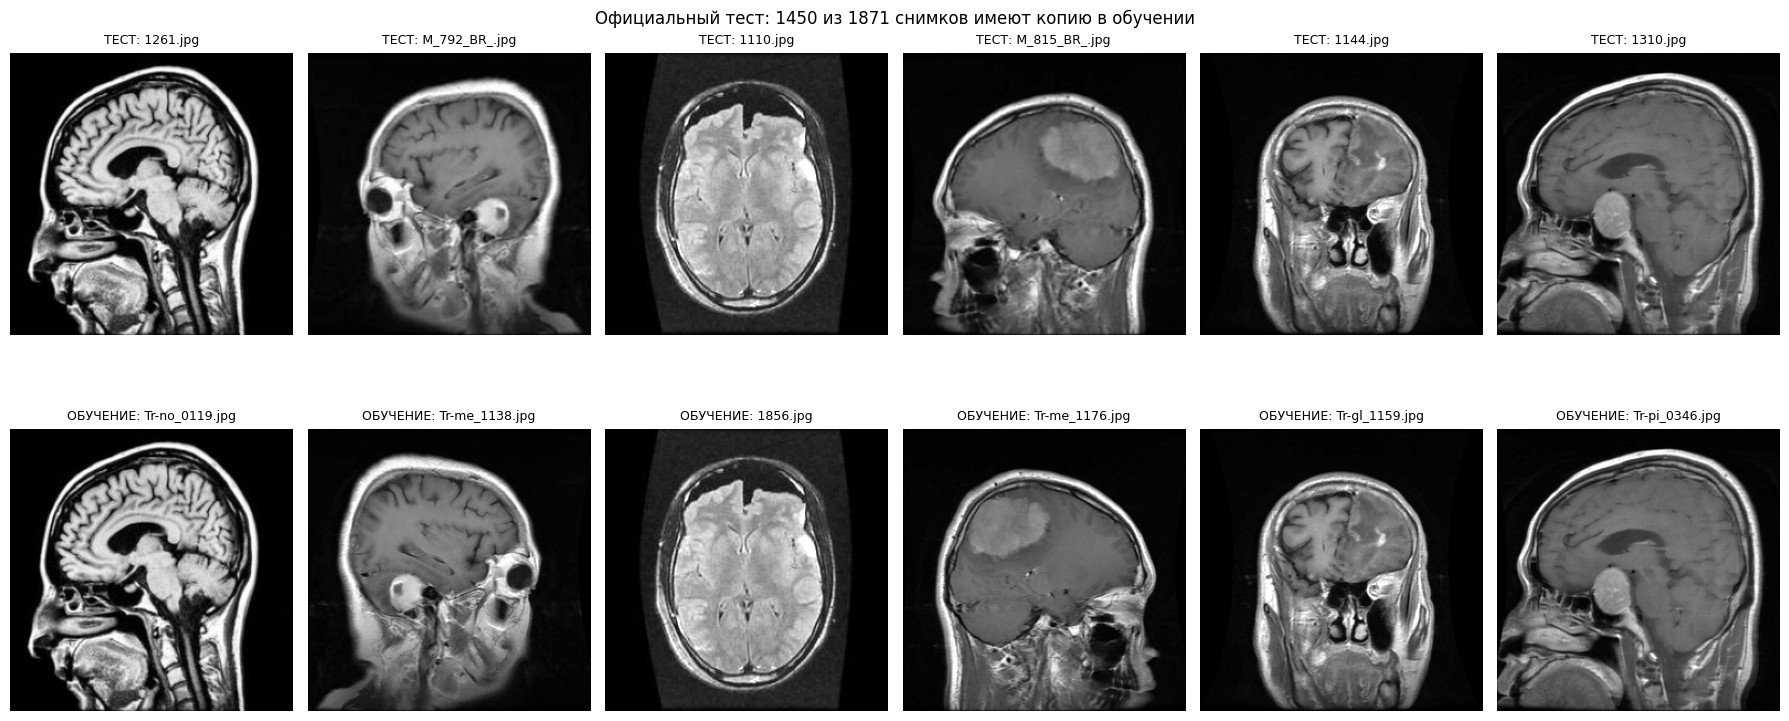

In [38]:
# === 4. ПРИМЕРЫ УТЕЧЕК: снимок из официального теста и его копия в обучении (картинка для презентации) ===
rs = np.random.RandomState(1)
cand = np.where(df.leak_copy.values)[0]
pick = rs.choice(cand, min(6, len(cand)), replace=False)
fig, ax = plt.subplots(2, max(len(pick), 1), figsize=(3*max(len(pick), 1), 7.4), squeeze=False)
for c, i in enumerate(pick):
    j = np.where((df.imgcomp.values == df.imgcomp.values[i]) & ~te)[0][0]
    ax[0, c].imshow(A[i], cmap='gray'); ax[0, c].set_title('ТЕСТ: ' + df.name[i][:20], fontsize=9)
    ax[1, c].imshow(A[j], cmap='gray'); ax[1, c].set_title('ОБУЧЕНИЕ: ' + df.name[j][:20], fontsize=9)
    ax[0, c].axis('off'); ax[1, c].axis('off')
plt.suptitle(f'Официальный тест: {df.leak_copy.sum()} из {te.sum()} снимков имеют копию в обучении', fontsize=12)
plt.tight_layout(); plt.subplots_adjust(hspace=0.25); plt.savefig(W/'figs'/'leak_examples.png', dpi=150); plt.show()

In [39]:
# === 5. ЧЕСТНОЕ РАЗБИЕНИЕ: по группам «пациент / снимок», а не по картинкам ===
from sklearn.model_selection import StratifiedGroupKFold
SPLIT = W/'split_v3.csv'
if SPLIT.exists():
    sv = pd.read_csv(SPLIT, keep_default_na=False).set_index('path')
    assert set(sv.index) == set(df.path), 'Набор файлов изменился: удали split_v3.csv в Drive'
    for col in ['part', 'test_unique', 'group', 'imgcomp', 'pid', 'fig_i']:
        df[col] = df.path.map(sv[col]).values
    df['test_unique'] = df.test_unique.astype(str).eq('True'); df['pid'] = df.pid.astype(str); df['fig_i'] = df.fig_i.astype(int)
    print('Разбиение загружено из Drive (то же, что раньше).')
else:
    idx = np.arange(n)
    rest, test = next(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(idx, LAB, df.group.values))
    tr_i, va_i = next(StratifiedGroupKFold(6, shuffle=True, random_state=SEED).split(rest, LAB[rest], df.group.values[rest]))
    part = np.array(['train'] * n, dtype=object); part[test] = 'test'; part[rest[va_i]] = 'val'
    df['part'] = part
    tm = (df.part == 'test') & (df.source != 'аугм. копии')
    df['test_unique'] = False
    df.loc[df[tm].drop_duplicates('imgcomp').index, 'test_unique'] = True
    df[['path', 'name', 'split', 'label', 'source', 'group', 'imgcomp', 'pid', 'fig_i', 'part', 'test_unique',
        'leak_copy', 'leak_patient']].to_csv(SPLIT, index=False)
    print('Разбиение создано и сохранено в Drive.')
for a_, b_ in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
    assert not (set(df.group[df.part == a_]) & set(df.group[df.part == b_])), (a_, b_)
use = ~df.label_conflict.values
TR = np.where((df.part == 'train').values & use)[0]; VA = np.where((df.part == 'val').values & use)[0]
TE = np.where((df.part == 'test').values & use)[0]; TEU = np.where(df.test_unique.values & use)[0]
print(pd.crosstab(df.part, df.label).rename(columns=dict(enumerate(CLASSES))))
print('Уникальных снимков в тесте (без копий и аугментаций):', len(TEU))
# разбиение Figshare для сегментации — по тем же пациентам
pid_part = {}
for p_, pt in zip(df.pid, df.part):
    if p_: assert pid_part.setdefault(p_, pt) == pt
fpart = np.array([pid_part.get(p_, 'train') for p_ in fpid])
s_tr, s_va, s_te = (np.where(fpart == k)[0] for k in ('train', 'val', 'test'))
print('Figshare пациентов train/val/test:', len(set(fpid[s_tr])), len(set(fpid[s_va])), len(set(fpid[s_te])),
      '| снимков:', len(s_tr), len(s_va), len(s_te))

Разбиение загружено из Drive (то же, что раньше).
label  Глиома  Менингиома  Гипофиз  Опухоли нет
part                                           
test      498         389      353          332
train    1971        1276     1636         1276
val       378         396      408          237
Уникальных снимков в тесте (без копий и аугментаций): 566
Figshare пациентов train/val/test: 152 38 43 | снимков: 2004 499 561


In [40]:
# === 6. КЛАССИФИКАТОР (EfficientNet-B0, веса ImageNet): есть ли опухоль и какого типа ===
import timm
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import f1_score, balanced_accuracy_score, confusion_matrix, accuracy_score, roc_auc_score
MEAN, STD = 0.449*255, 0.226*255
class CDS(Dataset):
    def __init__(s, idx, aug): s.idx, s.aug = np.asarray(idx), aug
    def __len__(s): return len(s.idx)
    def __getitem__(s, k):
        i = s.idx[k]; x = A[i].astype(np.float32)
        if s.aug:
            if random.random() < .5: x = x[:, ::-1]
            M_ = cv2.getRotationMatrix2D((128, 128), random.uniform(-15, 15), random.uniform(.9, 1.1))
            M_[:, 2] += np.random.uniform(-12, 12, 2)
            x = cv2.warpAffine(np.ascontiguousarray(x), M_, (256, 256), borderMode=cv2.BORDER_CONSTANT)
            x = x * random.uniform(.8, 1.2) + random.uniform(-20, 20)
            if random.random() < .3: x = cv2.GaussianBlur(x, (3, 3), 0)
            if random.random() < .3: x = x + np.random.normal(0, 5, x.shape)
        x = (np.clip(x, 0, 255) - MEAN) / STD
        return torch.tensor(x, dtype=torch.float32)[None].repeat(3, 1, 1), int(LAB[i])
def mk(idx, aug, bs=64): return DataLoader(CDS(idx, aug), bs, shuffle=aug, num_workers=2, drop_last=aug, pin_memory=True)

@torch.no_grad()
def cls_predict(m, idx, bs=128):
    m.eval(); P = []
    for x, _ in mk(idx, False, bs):
        x = x.to(dev)
        with torch.autocast('cuda'):
            p = m(x).float().softmax(1) + m(torch.flip(x, (3,))).float().softmax(1)
        P.append((p / 2).cpu())
    return torch.cat(P).numpy()

def train_cls(tr_idx, va_idx, tag, epochs=15, lr=3e-4):
    m = timm.create_model('efficientnet_b0', pretrained=True, num_classes=4).to(dev)
    dl = mk(tr_idx, True)
    opt = torch.optim.AdamW(m.parameters(), lr, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=epochs * len(dl), pct_start=.15)
    scaler = torch.cuda.amp.GradScaler(); crit = nn.CrossEntropyLoss(label_smoothing=.05)
    CK, BEST = W/'ckpt'/f'{tag}_last.pt', W/'ckpt'/f'{tag}_best.pt'
    start, best = 0, -1.0
    if CK.exists():
        c = torch.load(CK, map_location=dev, weights_only=False)
        m.load_state_dict(c['m']); opt.load_state_dict(c['o']); sch.load_state_dict(c['s']); scaler.load_state_dict(c['sc'])
        start, best = c['ep'] + 1, c['best']; print(f'[{tag}] продолжаю с эпохи', start + 1)
    for ep in range(start, epochs):
        m.train(); t0 = time.time(); tl = 0
        for x, y in dl:
            x, y = x.to(dev, non_blocking=True), y.to(dev, non_blocking=True); opt.zero_grad(set_to_none=True)
            with torch.autocast('cuda'): loss = crit(m(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sch.step(); tl += loss.item()
        P = cls_predict(m, va_idx); f1 = f1_score(LAB[va_idx], P.argmax(1), average='macro')
        if f1 > best: best = f1; torch.save(m.state_dict(), BEST)
        torch.save(dict(m=m.state_dict(), o=opt.state_dict(), s=sch.state_dict(), sc=scaler.state_dict(), ep=ep, best=best), CK)
        print(f'[{tag}] эпоха {ep+1}/{epochs}: loss {tl/len(dl):.3f}  val macroF1 {f1:.4f}  лучший {best:.4f}  {time.time()-t0:.0f}с')
    m.load_state_dict(torch.load(BEST, map_location=dev)); return m

model = train_cls(TR, VA, 'cls_v3', epochs=15)

/tmp/ipykernel_3748/1328469554.py:38: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(); crit = nn.CrossEntropyLoss(label_smoothing=.05)


[cls_v3] продолжаю с эпохи 16


{
 "val": {
  "n": 1419,
  "accuracy": 0.9147286821705426,
  "balanced_acc": 0.91806623077565,
  "macro_f1": 0.9190775202047909,
  "recall": {
   "Глиома": 0.843915343915344,
   "Менингиома": 0.9318181818181818,
   "Гипофиз": 0.9387254901960784,
   "Опухоли нет": 0.9578059071729957
  },
  "tumor_sens": 0.9915397631133672,
  "tumor_spec": 0.9578059071729957,
  "tumor_auc": 0.9964088614734378,
  "screen_thr": 0.7888955473899841,
  "screen_sens": 0.9796954314720813,
  "screen_spec": 0.9789029535864979
 },
 "test_group": {
  "n": 1572,
  "accuracy": 0.8778625954198473,
  "balanced_acc": 0.8920362351991039,
  "macro_f1": 0.8857792307154975,
  "recall": {
   "Глиома": 0.7449799196787149,
   "Менингиома": 0.9125964010282777,
   "Гипофиз": 0.9376770538243626,
   "Опухоли нет": 0.9728915662650602
  },
  "tumor_sens": 0.9806451612903225,
  "tumor_spec": 0.9728915662650602,
  "tumor_auc": 0.9944131364166342,
  "screen_thr": 0.7888955473899841,
  "screen_sens": 0.967741935483871,
  "screen_spec": 

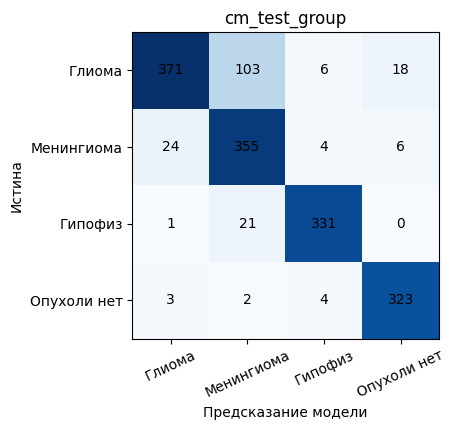


Точность по типу файлов:
                  mean  size
source                      
Br35H/прочие     1.000    10
Kaggle Tr/Te     0.922   630
P/G/M/N_n        0.778    72
SARTAJ-подобные  0.865   163
аугм. копии      0.798   411
числовые         0.923   286

Точность по исходному разрешению:
             mean  size
разрешение             
до 256      0.846   603
257-400     0.881    67
больше 400  0.899   902


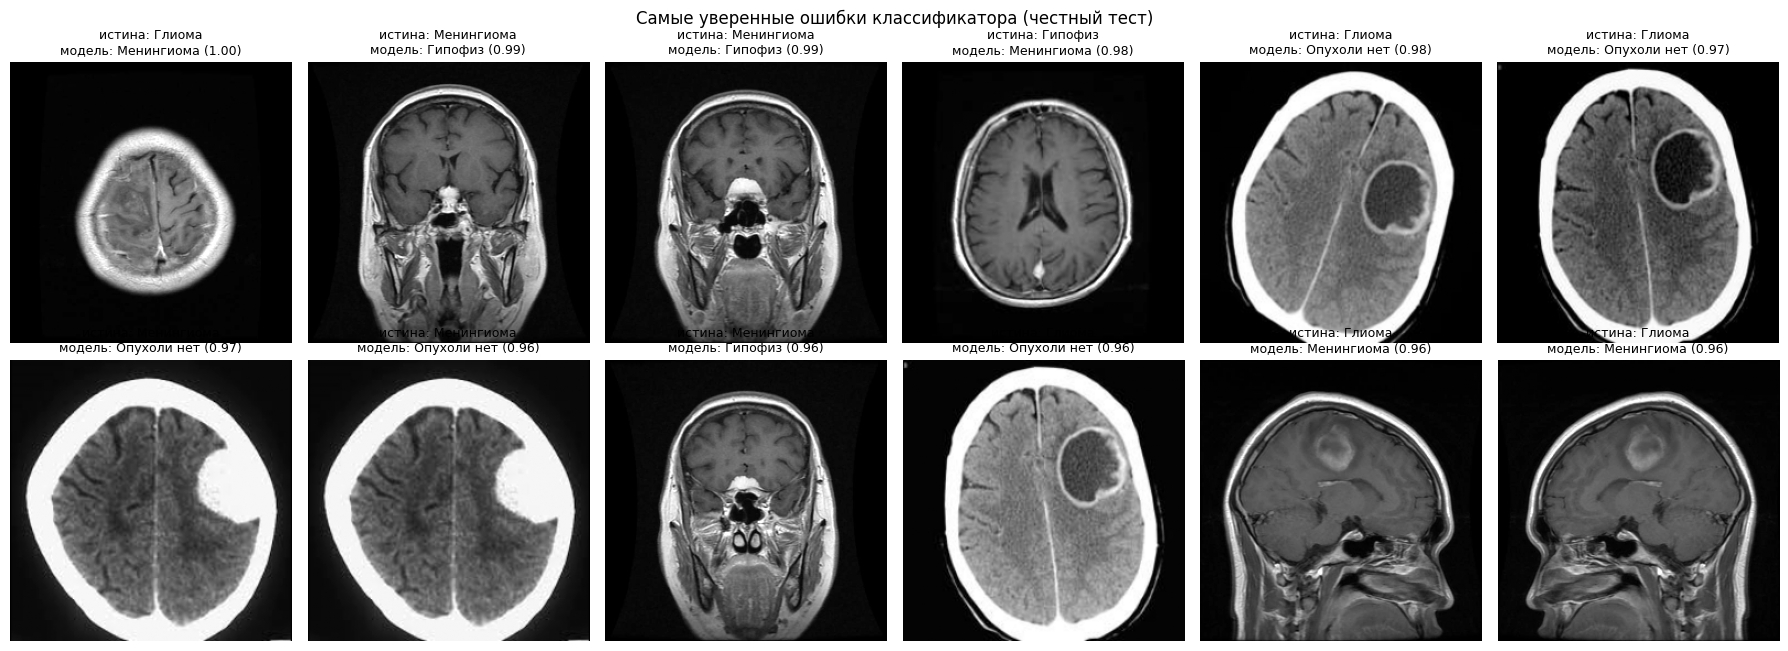

In [41]:
# === 7. ОЦЕНКА КЛАССИФИКАТОРА на честном тесте (группы не пересекаются с обучением) ===
def evaluate(P, Y, thr=None):
    pr = P.argmax(1); tt = Y != 3; pt = 1 - P[:, 3]
    r = dict(n=int(len(Y)), accuracy=float(accuracy_score(Y, pr)), balanced_acc=float(balanced_accuracy_score(Y, pr)),
             macro_f1=float(f1_score(Y, pr, average='macro')),
             recall={CLASSES[k]: (float((pr[Y == k] == k).mean()) if (Y == k).any() else None) for k in range(4)},
             tumor_sens=float(((pr != 3) & tt).sum() / max(tt.sum(), 1)),
             tumor_spec=float(((pr == 3) & ~tt).sum() / max((~tt).sum(), 1)),
             tumor_auc=(float(roc_auc_score(tt, pt)) if 0 < tt.sum() < len(Y) else None))
    if thr is not None:
        fl = pt >= thr
        r.update(screen_thr=float(thr), screen_sens=float((fl & tt).sum() / max(tt.sum(), 1)),
                 screen_spec=float((~fl & ~tt).sum() / max((~tt).sum(), 1)))
    return r
def cm_plot(Y, pr, name):
    cm = confusion_matrix(Y, pr, labels=range(4))
    fig, ax = plt.subplots(figsize=(5.2, 4.4)); ax.imshow(cm, cmap='Blues')
    for i in range(4):
        for j in range(4): ax.text(j, i, cm[i, j], ha='center', va='center', color='black')
    ax.set_xticks(range(4), CLASSES, rotation=25); ax.set_yticks(range(4), CLASSES)
    ax.set_xlabel('Предсказание модели'); ax.set_ylabel('Истина'); ax.set_title(name); plt.tight_layout()
    plt.savefig(W/'figs'/f'{name}.png', dpi=150); plt.show()

Pva = cls_predict(model, VA); Pte = cls_predict(model, TE)
THR_SCREEN = float(np.quantile((1 - Pva[:, 3])[LAB[VA] != 3], 0.02))   # порог «скрининга»: 98% чувствительности на val
pos = {i: k for k, i in enumerate(TE)}; Pteu = Pte[[pos[i] for i in TEU]]
RES = {'val': evaluate(Pva, LAB[VA], THR_SCREEN), 'test_group': evaluate(Pte, LAB[TE], THR_SCREEN),
       'test_group_unique': evaluate(Pteu, LAB[TEU], THR_SCREEN)}
print(json.dumps(RES, ensure_ascii=False, indent=1))
cm_plot(LAB[TE], Pte.argmax(1), 'cm_test_group')
t_ = df.iloc[TE].copy(); t_['верно'] = Pte.argmax(1) == LAB[TE]
t_['разрешение'] = pd.cut(t_[['h', 'w']].max(1), [0, 256, 400, 100000], labels=['до 256', '257-400', 'больше 400'])
print('\nТочность по типу файлов:'); print(t_.groupby('source')['верно'].agg(['mean', 'size']).round(3))
print('\nТочность по исходному разрешению:'); print(t_.groupby('разрешение', observed=True)['верно'].agg(['mean', 'size']).round(3))
# самые уверенные ошибки — для разбора
wrong = np.where(Pte.argmax(1) != LAB[TE])[0]; order = wrong[np.argsort(-Pte[wrong].max(1))][:12]
fig, ax = plt.subplots(2, 6, figsize=(18, 6.6), squeeze=False)
for a_, k in zip(ax.flat, order):
    i = TE[k]; a_.imshow(A[i], cmap='gray')
    a_.set_title(f'истина: {CLASSES[LAB[i]]}\nмодель: {CLASSES[Pte[k].argmax()]} ({Pte[k].max():.2f})', fontsize=9)
for a_ in ax.flat: a_.axis('off')
plt.suptitle('Самые уверенные ошибки классификатора (честный тест)'); plt.tight_layout()
plt.savefig(W/'figs'/'cls_errors.png', dpi=150); plt.show()
json.dump(RES, open(W/'results_cls_v3.json', 'w'), ensure_ascii=False, indent=1)

In [42]:
# === 8. СЕГМЕНТАЦИЯ (U-Net ResNet34): контур опухоли ===
# Обучение: Figshare (train-пациенты) + снимки организаторов этих же пациентов с перенесёнными масками
# + снимки «нет опухоли» с пустой маской (учим НЕ рисовать опухоль там, где её нет).
import segmentation_models_pytorch as smp
def d8(x, t):
    y = np.rot90(x, t // 2); return np.fliplr(y) if t % 2 else y
def z1(v):
    v = v.ravel() - v.mean(); return v / (np.linalg.norm(v) + 1e-6)
fs64 = small(fX); a64 = small(A)
om_idx = np.where(df.pid.values != '')[0]
OM = np.zeros((len(om_idx), 256, 256), np.uint8); om_c = np.zeros(len(om_idx))
for q, i in enumerate(om_idx):
    fi = int(df.fig_i.values[i]); a_ = z1(a64[i])
    cs = [float(a_ @ z1(d8(fs64[fi], t).copy())) for t in range(8)]
    t = int(np.argmax(cs)); om_c[q] = cs[t]; OM[q] = d8(fM[fi], t).copy()
print(f'Маски перенесены на {len(om_idx)} снимков организаторов; корреляция с оригиналом: средняя {om_c.mean():.4f}, минимум {om_c.min():.4f}')
part = df.part.values
q_tr = [q for q, i in enumerate(om_idx) if part[i] == 'train']
q_te = [q for q, i in enumerate(om_idx) if part[i] == 'test']
ITR = [('f', i) for i in s_tr] + [('o', q) for q in q_tr] + [('n', i) for i in TR if LAB[i] == 3]
ZERO = np.zeros((256, 256), np.uint8)
def get_xm(src, i):
    if src == 'f': return fX[i], fM[i]
    if src == 'o': return A[om_idx[i]], OM[i]
    return A[i], ZERO
class SDS(Dataset):
    def __init__(s, items, aug): s.items, s.aug = items, aug
    def __len__(s): return len(s.items)
    def __getitem__(s, k):
        x, m = get_xm(*s.items[k]); x = x.astype(np.float32); m = m.astype(np.float32)
        if s.aug:
            if random.random() < .5: x, m = x[:, ::-1], m[:, ::-1]
            if random.random() < .5: x, m = x[::-1], m[::-1]
            M_ = cv2.getRotationMatrix2D((128, 128), random.uniform(-20, 20), random.uniform(.85, 1.15))
            x = cv2.warpAffine(np.ascontiguousarray(x), M_, (256, 256))
            m = cv2.warpAffine(np.ascontiguousarray(m), M_, (256, 256), flags=cv2.INTER_NEAREST)
            x = x * random.uniform(.8, 1.2) + random.uniform(-20, 20)
        x = (np.clip(x, 0, 255) - MEAN) / STD
        return torch.tensor(x, dtype=torch.float32)[None], torch.tensor(np.ascontiguousarray(m), dtype=torch.float32)[None]
def arrays(items):
    xm = [get_xm(s_, i) for s_, i in items]
    return np.stack([a for a, _ in xm]), np.stack([b for _, b in xm])
def dice_np(p, m):
    inter = (p & m).sum((1, 2)); den = p.sum((1, 2)) + m.sum((1, 2))
    return (2 * inter + 1e-6) / (den + 1e-6)

seg = smp.Unet('resnet34', encoder_weights='imagenet', in_channels=1, classes=1).to(dev)
@torch.no_grad()
def seg_probs(xs):
    seg.eval(); out = []
    for s in range(0, len(xs), 32):
        x = torch.tensor((xs[s:s+32].astype(np.float32) - MEAN) / STD)[:, None].to(dev)
        with torch.autocast('cuda'):
            p = torch.sigmoid(seg(x).float()) + torch.flip(torch.sigmoid(seg(torch.flip(x, (3,))).float()), (3,))
        out.append((p / 2).cpu().numpy()[:, 0])
    return np.concatenate(out) if out else np.zeros((0, 256, 256), np.float32)

dice_loss = smp.losses.DiceLoss('binary'); bce = nn.BCEWithLogitsLoss()
SEP = 20
sdl = DataLoader(SDS(ITR, True), 16, shuffle=True, num_workers=2, drop_last=True, pin_memory=True)
XV, MV = arrays([('f', i) for i in s_va])
sopt = torch.optim.AdamW(seg.parameters(), 3e-4, weight_decay=1e-4)
ssch = torch.optim.lr_scheduler.OneCycleLR(sopt, 3e-4, total_steps=SEP * len(sdl), pct_start=.1)
sscaler = torch.cuda.amp.GradScaler()
SCK, SBEST = W/'ckpt'/'seg_v3_last.pt', W/'ckpt'/'seg_v3_best.pt'
sstart, sbest = 0, -1.0
if SCK.exists():
    c = torch.load(SCK, map_location=dev, weights_only=False)
    seg.load_state_dict(c['m']); sopt.load_state_dict(c['o']); ssch.load_state_dict(c['s']); sscaler.load_state_dict(c['sc'])
    sstart, sbest = c['ep'] + 1, c['best']; print('Сегментация: продолжаю с эпохи', sstart + 1)
print('Обучающих примеров для сегментации:', len(ITR))
for ep in range(sstart, SEP):
    seg.train(); t0 = time.time(); tl = 0
    for x, y in sdl:
        x, y = x.to(dev, non_blocking=True), y.to(dev, non_blocking=True); sopt.zero_grad(set_to_none=True)
        with torch.autocast('cuda'):
            o = seg(x).float(); loss = dice_loss(o, y) + bce(o, y)
        sscaler.scale(loss).backward(); sscaler.step(sopt); sscaler.update(); ssch.step(); tl += loss.item()
    d = dice_np(seg_probs(XV) > .5, MV > 0).mean()
    if d > sbest: sbest = d; torch.save(seg.state_dict(), SBEST)
    torch.save(dict(m=seg.state_dict(), o=sopt.state_dict(), s=ssch.state_dict(), sc=sscaler.state_dict(), ep=ep, best=sbest), SCK)
    print(f'[seg] эпоха {ep+1}/{SEP}: loss {tl/len(sdl):.3f}  val Dice {d:.4f}  лучший {sbest:.4f}  {time.time()-t0:.0f}с')
seg.load_state_dict(torch.load(SBEST, map_location=dev))

Маски перенесены на 5936 снимков организаторов; корреляция с оригиналом: средняя 0.9994, минимум 0.9803


/tmp/ipykernel_3748/3494562806.py:64: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  sscaler = torch.cuda.amp.GradScaler()


Сегментация: продолжаю с эпохи 21
Обучающих примеров для сегментации: 7237


<All keys matched successfully>

{
 "figshare_test_patients": 43,
 "figshare_test_images": 561,
 "dice_mean": 0.7899739812261583,
 "dice_median": 0.8911042945620365,
 "share_dice_over_0_5": 0.8841354723707665,
 "dice_by_class": {
  "Глиома": 0.6973540925462772,
  "Менингиома": 0.903442774529001,
  "Гипофиз": 0.8361003388490851
 },
 "org_test_images_with_mask": 990,
 "org_dice_mean": 0.8188033026733734,
 "org_share_dice_over_0_5": 0.9101010101010101,
 "end_to_end_found_and_localized": 0.896969696969697,
 "healthy_test_images": 332,
 "healthy_false_contour_rate": 0.0
}


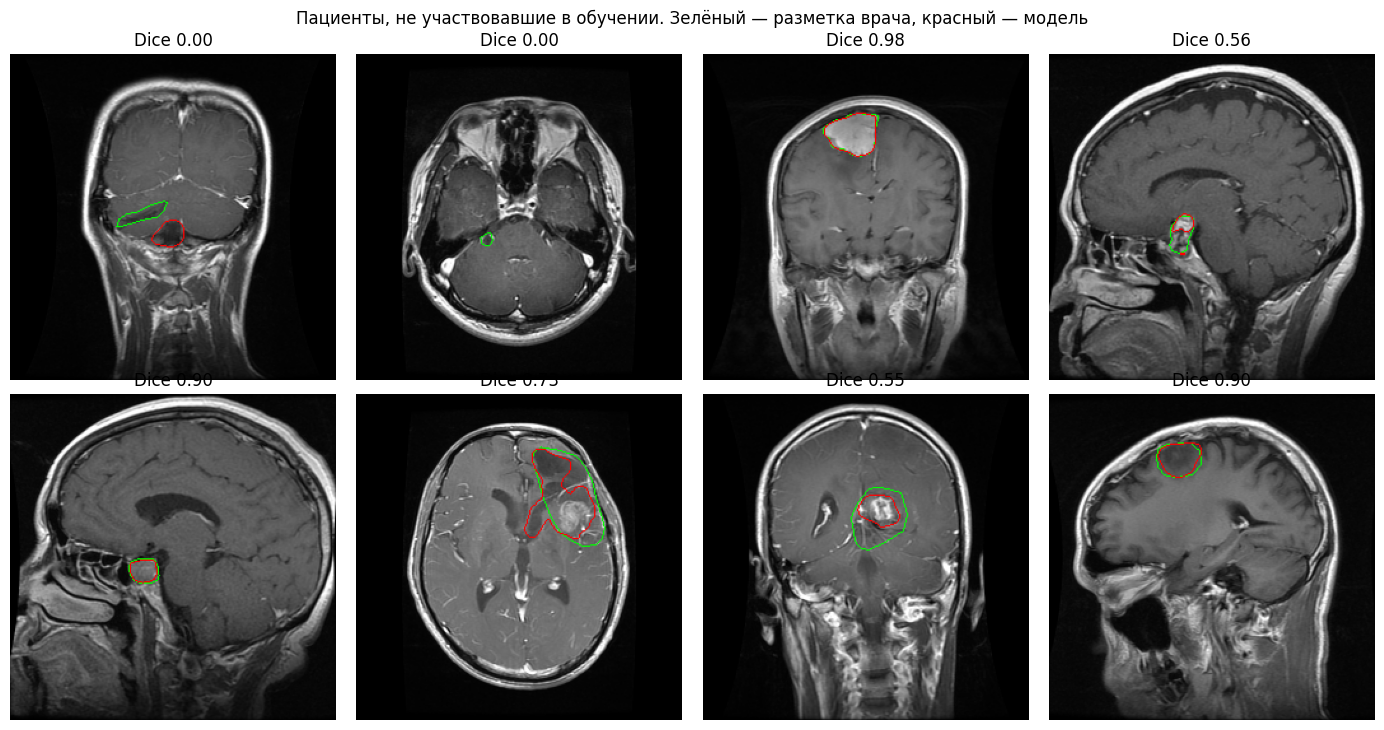

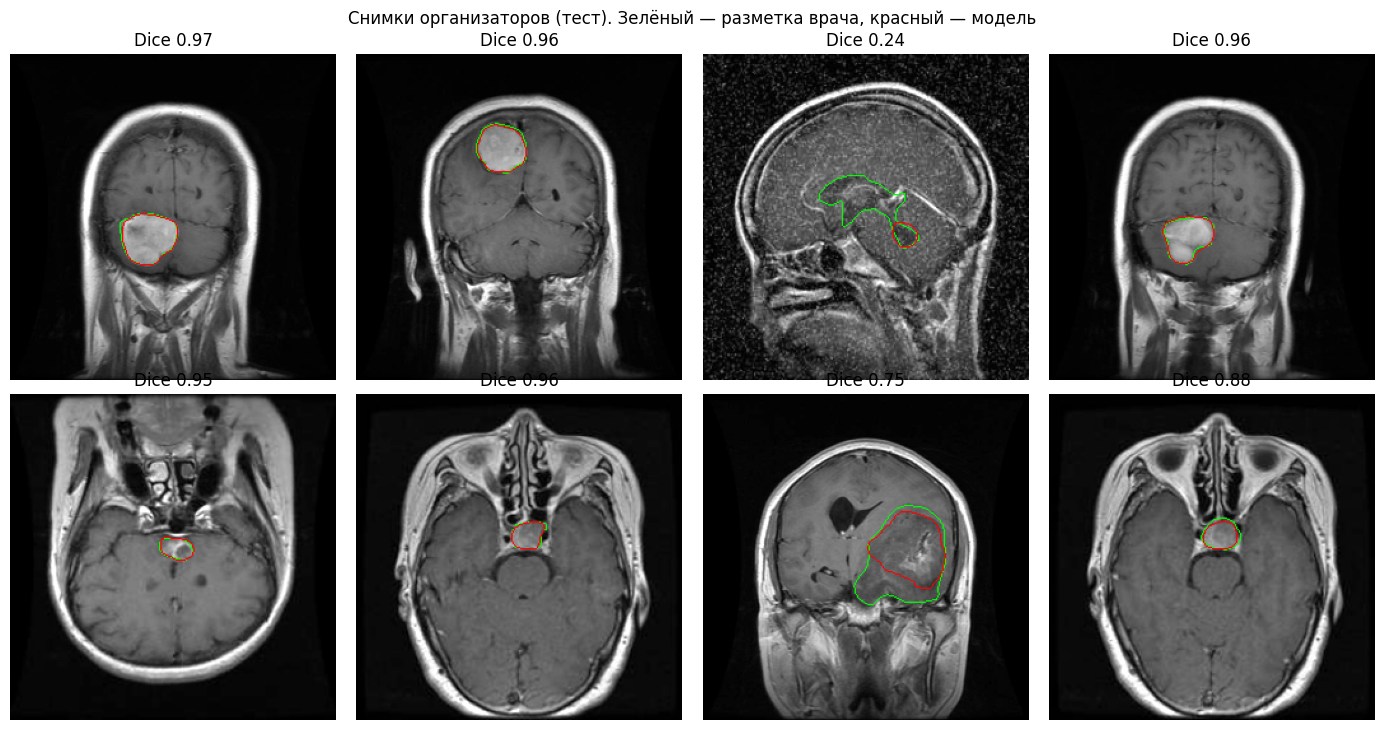

In [43]:
# === 9. ОЦЕНКА СЕГМЕНТАЦИИ: невиденные пациенты, снимки организаторов, ложные контуры на здоровых ===
XF, MF = arrays([('f', i) for i in s_te]); dF = dice_np(seg_probs(XF) > .5, MF > 0)
SR = dict(figshare_test_patients=len(set(fpid[s_te])), figshare_test_images=int(len(dF)),
          dice_mean=float(dF.mean()), dice_median=float(np.median(dF)), share_dice_over_0_5=float((dF > .5).mean()),
          dice_by_class={CLASSES[k]: float(dF[fy[s_te] == k].mean()) for k in range(3) if (fy[s_te] == k).any()})
if q_te:
    XO, MO = arrays([('o', q) for q in q_te]); dO = dice_np(seg_probs(XO) > .5, MO > 0)
    io = om_idx[q_te]; Pio = cls_predict(model, io); flagged = (1 - Pio[:, 3]) >= THR_SCREEN
    SR.update(org_test_images_with_mask=int(len(dO)), org_dice_mean=float(dO.mean()), org_share_dice_over_0_5=float((dO > .5).mean()),
              end_to_end_found_and_localized=float(((dO > .5) & flagged).mean()))
nt = [i for i in TE if LAB[i] == 3]
if nt:
    pn = seg_probs(A[nt]) > .5
    SR['healthy_test_images'] = len(nt); SR['healthy_false_contour_rate'] = float((pn.mean((1, 2)) > .005).mean())
print(json.dumps(SR, ensure_ascii=False, indent=1)); json.dump(SR, open(W/'results_seg_v3.json', 'w'), ensure_ascii=False, indent=1)

def show_cases(X_, M_, d_, title, fname, k=8):
    sel = np.random.RandomState(0).choice(len(X_), min(k, len(X_)), replace=False)
    pm = seg_probs(X_[sel]) > .5
    fig, ax = plt.subplots(2, 4, figsize=(14, 7.4), squeeze=False)
    for a_, j, p in zip(ax.flat, sel, pm):
        rgb = cv2.cvtColor(X_[j], cv2.COLOR_GRAY2RGB)
        cg, _ = cv2.findContours(M_[j].astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cp, _ = cv2.findContours(p.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(rgb, cg, -1, (0, 255, 0), 1); cv2.drawContours(rgb, cp, -1, (255, 0, 0), 1)
        a_.imshow(rgb); a_.set_title(f'Dice {d_[j]:.2f}')
    for a_ in ax.flat: a_.axis('off')
    plt.suptitle(title); plt.tight_layout(); plt.savefig(W/'figs'/fname, dpi=150); plt.show()
show_cases(XF, MF, dF, 'Пациенты, не участвовавшие в обучении. Зелёный — разметка врача, красный — модель', 'seg_examples_figshare.png')
if q_te: show_cases(XO, MO, dO, 'Снимки организаторов (тест). Зелёный — разметка врача, красный — модель', 'seg_examples_org.png')

In [44]:
# === 10. ПОЧЕМУ ВАЖНА ЧЕСТНАЯ ОЦЕНКА: та же модель, обученная и проверенная на официальном разбиении ===
off_tr = np.where((df.split == 'train').values & use)[0]; off_te = np.where((df.split == 'test').values & use)[0]
perm = np.random.RandomState(SEED).permutation(off_tr); nv = int(.15 * len(perm))
naive = train_cls(perm[nv:], perm[:nv], 'cls_naive_v3', epochs=10)
RN = evaluate(cls_predict(naive, off_te), LAB[off_te])
json.dump(RN, open(W/'results_naive_v3.json', 'w'), ensure_ascii=False, indent=1)
print('Официальный тест (с утечкой):  accuracy', round(RN['accuracy'], 4), ' macroF1', round(RN['macro_f1'], 4))
print('Честный групповой тест:        accuracy', round(RES['test_group']['accuracy'], 4), ' macroF1', round(RES['test_group']['macro_f1'], 4))
del naive; torch.cuda.empty_cache()

/tmp/ipykernel_3748/1328469554.py:38: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(); crit = nn.CrossEntropyLoss(label_smoothing=.05)


[cls_naive_v3] продолжаю с эпохи 11
Официальный тест (с утечкой):  accuracy 0.9588  macroF1 0.9585
Честный групповой тест:        accuracy 0.8779  macroF1 0.8858


In [45]:
# === 11. ИТОГИ ДЛЯ ПРЕЗЕНТАЦИИ (сохраняются в Drive: summary_v3.md) ===
R, U = RES['test_group'], RES['test_group_unique']
L = [
 '# Итоги (v3)',
 f'Данные: {n} снимков организаторов (из 12064) + Figshare: 3064 снимка, 233 пациента, маски врачей.',
 f'Аудит: {audit["test_with_copy_in_train"]} из {audit["test_images"]} снимков официального теста имеют копию в обучении; '
 f'{audit["test_with_copy_or_same_patient_in_train"]} — копию или того же пациента.',
 f'Найдено {audit["figshare_patients_found"]} пациентов Figshare внутри данных организаторов ({audit["org_images_matched_to_figshare"]} снимков).',
 '## Классификация (честный тест, группы не пересекаются с обучением)',
 f'Все снимки теста: n={R["n"]}, accuracy {R["accuracy"]:.3f}, balanced acc {R["balanced_acc"]:.3f}, macro-F1 {R["macro_f1"]:.3f}',
 f'Уникальные снимки: n={U["n"]}, accuracy {U["accuracy"]:.3f}, macro-F1 {U["macro_f1"]:.3f}',
 f'Опухоль/норма: чувствительность {R["tumor_sens"]:.3f}, специфичность {R["tumor_spec"]:.3f}, AUC {R["tumor_auc"]:.3f}',
 f'Режим скрининга (порог {R["screen_thr"]:.3f}): чувствительность {R["screen_sens"]:.3f}, специфичность {R["screen_spec"]:.3f}',
 '## Сегментация',
 f'Невиденные пациенты Figshare ({SR["figshare_test_patients"]} пац., {SR["figshare_test_images"]} снимков): '
 f'Dice средний {SR["dice_mean"]:.3f}, медиана {SR["dice_median"]:.3f}, доля Dice>0.5 {SR["share_dice_over_0_5"]:.3f}',
]
if 'org_dice_mean' in SR:
    L.append(f'Снимки организаторов (тест, {SR["org_test_images_with_mask"]} с маской): Dice {SR["org_dice_mean"]:.3f}; '
             f'найдено и локализовано (классификатор + Dice>0.5): {SR["end_to_end_found_and_localized"]:.3f}')
if 'healthy_false_contour_rate' in SR:
    L.append(f'Ложные контуры на здоровых снимках: {SR["healthy_false_contour_rate"]:.3f} из {SR["healthy_test_images"]}')
if (W/'results_naive_v3.json').exists():
    RN = json.load(open(W/'results_naive_v3.json'))
    L.append(f'## Наивная оценка на официальном тесте (с утечкой): accuracy {RN["accuracy"]:.3f}, macro-F1 {RN["macro_f1"]:.3f}')
txt = '\n'.join(L); print(txt); open(W/'summary_v3.md', 'w').write(txt)

# Итоги (v3)
Данные: 9150 снимков организаторов (из 12064) + Figshare: 3064 снимка, 233 пациента, маски врачей.
Аудит: 1450 из 1871 снимков официального теста имеют копию в обучении; 1642 — копию или того же пациента.
Найдено 231 пациентов Figshare внутри данных организаторов (5936 снимков).
## Классификация (честный тест, группы не пересекаются с обучением)
Все снимки теста: n=1572, accuracy 0.878, balanced acc 0.892, macro-F1 0.886
Уникальные снимки: n=566, accuracy 0.876, macro-F1 0.881
Опухоль/норма: чувствительность 0.981, специфичность 0.973, AUC 0.994
Режим скрининга (порог 0.789): чувствительность 0.968, специфичность 0.976
## Сегментация
Невиденные пациенты Figshare (43 пац., 561 снимков): Dice средний 0.790, медиана 0.891, доля Dice>0.5 0.884
Снимки организаторов (тест, 990 с маской): Dice 0.819; найдено и локализовано (классификатор + Dice>0.5): 0.897
Ложные контуры на здоровых снимках: 0.000 из 332
## Наивная оценка на официальном тесте (с утечкой): accuracy 0.959, macro-F1

1006

--- Tr-no_0362.jpg (истина: Опухоли нет)
Вероятность опухоли: 2% (порог скрининга 0.79).
Признаков опухоли не найдено.
Исследовательский прототип, не медицинское изделие. Решение принимает врач.

--- Tr-me_0393.jpg (истина: Менингиома)
Вероятность опухоли: 99% (порог скрининга 0.79).
Наиболее вероятный тип: Менингиома (96%).
Выделенная область: 1.6% площади среза, в верхней центральной части изображения; уверенность контура 99%.
Исследовательский прототип, не медицинское изделие. Решение принимает врач.

--- Tr-gl_0684.jpg (истина: Глиома)
Вероятность опухоли: 99% (порог скрининга 0.79).
Наиболее вероятный тип: Глиома (96%).
Выделенная область: 1.1% площади среза, в верхней центральной части изображения; уверенность контура 97%.
Исследовательский прототип, не медицинское изделие. Решение принимает врач.

--- P_744.jpg (истина: Гипофиз)
Вероятность опухоли: 99% (порог скрининга 0.79).
Наиболее вероятный тип: Гипофиз (97%).
Выделенная область: 0.6% площади среза, в средней центральной ча

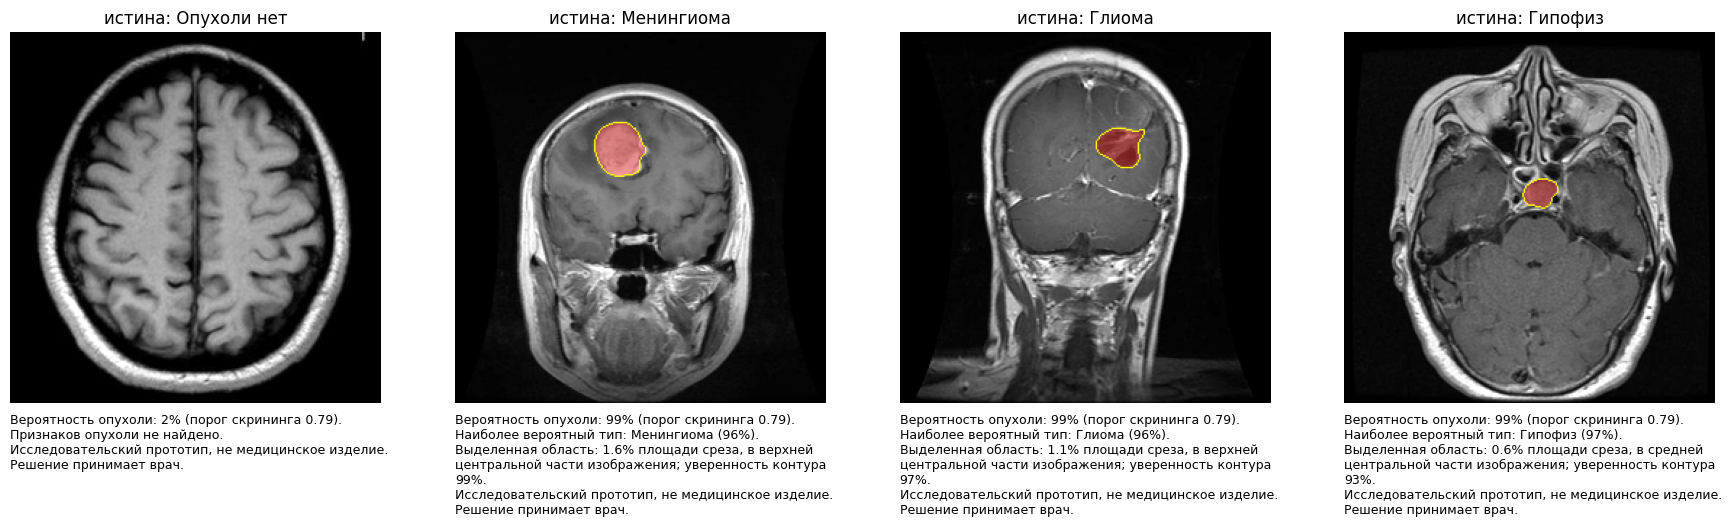

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://412bd0d7f0e8a3361b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [46]:
# === 12. ПРОТОТИП ДЛЯ ВРАЧА: загрузка снимка -> вероятность, тип, контур, пояснение ===
import gradio as gr
def place(m):
    ys, xs = np.nonzero(m); cy, cx = ys.mean() / 256, xs.mean() / 256
    v = 'верхней' if cy < .4 else ('нижней' if cy > .6 else 'средней')
    h = 'левой' if cx < .4 else ('правой' if cx > .6 else 'центральной')
    return f'в {v} {h} части изображения'
def analyze(img):
    if img is None: return None, None, 'Загрузите снимок МРТ (JPG/PNG).'
    g = np.array(Image.fromarray(img).convert('L')); x256 = prep(g)
    x = torch.tensor((x256.astype(np.float32) - MEAN) / STD)[None, None].repeat(1, 3, 1, 1).to(dev)
    model.eval()
    with torch.no_grad(), torch.autocast('cuda'):
        p = ((model(x).float().softmax(1) + model(torch.flip(x, (3,))).float().softmax(1)) / 2).cpu().numpy()[0]
    probs = {CLASSES[k]: float(p[k]) for k in range(4)}; p_t = 1 - p[3]
    pm = seg_probs(x256[None])[0]; m = (pm > .5).astype(np.uint8)
    k_, lab_, st, _ = cv2.connectedComponentsWithStats(m)
    for c in range(1, k_):
        if st[c, cv2.CC_STAT_AREA] < 30: m[lab_ == c] = 0
    rgb = cv2.cvtColor(x256, cv2.COLOR_GRAY2RGB)
    lines = [f'Вероятность опухоли: {p_t:.0%} (порог скрининга {THR_SCREEN:.2f}).']
    if p_t >= THR_SCREEN:
        top = int(np.argmax(p[:3])); lines.append(f'Наиболее вероятный тип: {CLASSES[top]} ({p[top]:.0%}).')
        if m.sum():
            ov = rgb.copy(); ov[m > 0] = (255, 0, 0); rgb = cv2.addWeighted(rgb, .65, ov, .35, 0)
            cs, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE); cv2.drawContours(rgb, cs, -1, (255, 255, 0), 1)
            lines.append(f'Выделенная область: {100*m.mean():.1f}% площади среза, {place(m)}; уверенность контура {pm[m > 0].mean():.0%}.')
        else:
            lines.append('Классификатор подозревает опухоль, но контур не выделен — нужен внимательный просмотр врачом.')
    else:
        lines.append('Признаков опухоли не найдено.')
    if p.max() < .6 or .3 < p_t < .7: lines.append('ВНИМАНИЕ: низкая уверенность модели — приоритетный просмотр врачом.')
    lines.append('Исследовательский прототип, не медицинское изделие. Решение принимает врач.')
    return probs, rgb, '\n'.join(lines)
# запасные «скриншоты» прототипа на тестовых снимках
demo_idx = [TE[k] for k in np.random.RandomState(3).choice(len(TE), 4, replace=False)]
import textwrap
fig, ax = plt.subplots(1, 4, figsize=(22, 9), squeeze=False)
for a_, i in zip(ax.flat, demo_idx):
    pr_, im_, tx_ = analyze(cv2.cvtColor(A[i], cv2.COLOR_GRAY2RGB))
    a_.imshow(im_); a_.axis('off'); a_.set_title(f'истина: {CLASSES[LAB[i]]}', fontsize=12)
    a_.text(0, -0.03, '\n'.join(textwrap.fill(l, 52) for l in tx_.split('\n')), transform=a_.transAxes, va='top', fontsize=9)
    print(f'--- {df.name[i]} (истина: {CLASSES[LAB[i]]})\n{tx_}\n')
plt.savefig(W/'figs'/'demo_cases.png', dpi=130, bbox_inches='tight'); plt.show()
gr.Interface(analyze, gr.Image(type='numpy', label='Снимок МРТ'),
             [gr.Label(num_top_classes=4, label='Вероятности'), gr.Image(label='Результат'), gr.Textbox(label='Пояснение', lines=6)],
             title='МРТ головного мозга: обнаружение и локализация опухоли',
             description='Загрузите срез МРТ (T1 с контрастом). Система покажет вероятность опухоли, её тип и выделит область.'
             ).launch(share=True, debug=False)

In [47]:
# === 13. ПРОВЕРКИ ЧЕСТНОСТИ (для жюри) ===
from sklearn.ensemble import HistGradientBoostingClassifier
VER = {}
Zc = zt(S64).to(dev); Zd = [zt(d8_t(S64, t)).to(dev) for t in range(8)]
def nearest(test_idx, train_idx):
    T = Zc[torch.as_tensor(np.asarray(train_idx), device=dev)]; out = []
    for s in range(0, len(test_idx), 512):
        q = torch.as_tensor(np.asarray(test_idx[s:s+512]), device=dev)
        c = torch.stack([Zd[t][q] @ T.T for t in range(8)]).max(0).values.max(1).values
        out.append(c.cpu().numpy())
    return np.concatenate(out)
nn_ours = nearest(TE, TR); nn_off = nearest(np.where(te)[0], np.where(~te)[0])
del Zc, Zd; torch.cuda.empty_cache()
for nm, v in [('Наш тест', nn_ours), ('Официальный тест', nn_off)]:
    print(f'{nm}: имеют копию в обучении (corr>=0.98) {np.mean(v >= .98):.1%}; очень похожий снимок (0.95-0.98) {np.mean((v >= .95) & (v < .98)):.1%}')
VER['test_with_copy_in_train'] = {'ours': float(np.mean(nn_ours >= .98)), 'official': float(np.mean(nn_off >= .98))}
def meta(idx):
    idx = np.asarray(idx); a = A[idx].reshape(len(idx), -1).astype(np.float32)
    sz = np.array([os.path.getsize(df.path.iat[i]) for i in idx])
    return np.c_[df.h.values[idx], df.w.values[idx], df.h.values[idx] / df.w.values[idx], np.log(sz), a.mean(1), a.std(1), (a < 10).mean(1)]
gb = HistGradientBoostingClassifier(random_state=SEED).fit(meta(TR), LAB[TR])
acc_meta = float((gb.predict(meta(TE)) == LAB[TE]).mean())
acc_major = float(np.bincount(LAB[TE]).max() / len(TE))
print(f'Угадывание самым частым классом: {acc_major:.3f}; модель только по метаданным: {acc_meta:.3f}; наша модель: {RES["test_group"]["accuracy"]:.3f}')
VER.update(acc_majority=acc_major, acc_metadata_only=acc_meta)
LAB_true = LAB.copy(); rs_ = np.random.RandomState(0)
LAB = LAB_true.copy(); LAB[TR] = rs_.permutation(LAB_true[TR]); LAB[VA] = rs_.permutation(LAB_true[VA])
perm_model = train_cls(TR, VA, 'cls_perm_v3', epochs=3)
LAB = LAB_true
acc_perm = float((cls_predict(perm_model, TE).argmax(1) == LAB[TE]).mean())
del perm_model; torch.cuda.empty_cache()
print(f'Обучение на ПЕРЕМЕШАННЫХ метках -> accuracy на тесте {acc_perm:.3f} (ожидаем около {acc_major:.2f}, т.е. ничего не выучено)')
VER['acc_permuted_labels'] = acc_perm
def boot(fn, groups, n=1000, seed=0):
    rs2 = np.random.RandomState(seed); ug = np.unique(groups); by = {g: np.where(groups == g)[0] for g in ug}; vals = []
    for _ in range(n):
        ii = np.concatenate([by[g] for g in rs2.choice(ug, len(ug), replace=True)]); vals.append(fn(ii))
    return [round(float(x), 4) for x in np.percentile(vals, [2.5, 97.5])]
gT, yT, pT = df.group.values[TE], LAB[TE], Pte.argmax(1)
CI = dict(accuracy=boot(lambda ii: (pT[ii] == yT[ii]).mean(), gT),
          macro_f1=boot(lambda ii: f1_score(yT[ii], pT[ii], average='macro'), gT),
          tumor_sens=boot(lambda ii: ((pT[ii] != 3) & (yT[ii] != 3)).sum() / max((yT[ii] != 3).sum(), 1), gT),
          tumor_spec=boot(lambda ii: ((pT[ii] == 3) & (yT[ii] == 3)).sum() / max((yT[ii] == 3).sum(), 1), gT),
          seg_dice_figshare=boot(lambda ii: dF[ii].mean(), fpid[s_te]))
print('95% ДИ:', json.dumps(CI, ensure_ascii=False)); VER['ci95'] = CI
pv = 1 - Pva[:, 3]
THR_SCREEN = float(min(0.5, np.quantile(pv[LAB[VA] != 3], 0.01)))
pt_ = 1 - Pte[:, 3]; tt_ = LAB[TE] != 3; fl = pt_ >= THR_SCREEN
VER['screening'] = dict(thr=THR_SCREEN, sens=float((fl & tt_).sum() / tt_.sum()), spec=float((~fl & ~tt_).sum() / (~tt_).sum()))
print('Режим скрининга (демо уже использует новый порог):', VER['screening'])
json.dump(VER, open(W/'verification_v3.json', 'w'), ensure_ascii=False, indent=1)
print('\n' + open(W/'summary_v3.md').read())

Наш тест: имеют копию в обучении (corr>=0.98) 0.7%; очень похожий снимок (0.95-0.98) 4.6%
Официальный тест: имеют копию в обучении (corr>=0.98) 77.4%; очень похожий снимок (0.95-0.98) 3.3%
Угадывание самым частым классом: 0.317; модель только по метаданным: 0.607; наша модель: 0.878


/tmp/ipykernel_3748/1328469554.py:38: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(); crit = nn.CrossEntropyLoss(label_smoothing=.05)


[cls_perm_v3] продолжаю с эпохи 4
Обучение на ПЕРЕМЕШАННЫХ метках -> accuracy на тесте 0.220 (ожидаем около 0.32, т.е. ничего не выучено)
95% ДИ: {"accuracy": [0.8237, 0.9239], "macro_f1": [0.8337, 0.9232], "tumor_sens": [0.9618, 0.9938], "tumor_spec": [0.9439, 0.9911], "seg_dice_figshare": [0.7522, 0.829]}
Режим скрининга (демо уже использует новый порог): {'thr': 0.5, 'sens': 0.9822580645161291, 'spec': 0.9728915662650602}

# Итоги (v3)
Данные: 9150 снимков организаторов (из 12064) + Figshare: 3064 снимка, 233 пациента, маски врачей.
Аудит: 1450 из 1871 снимков официального теста имеют копию в обучении; 1642 — копию или того же пациента.
Найдено 231 пациентов Figshare внутри данных организаторов (5936 снимков).
## Классификация (честный тест, группы не пересекаются с обучением)
Все снимки теста: n=1572, accuracy 0.878, balanced acc 0.892, macro-F1 0.886
Уникальные снимки: n=566, accuracy 0.876, macro-F1 0.881
Опухоль/норма: чувствительность 0.981, специфичность 0.973, AUC 0.994
Режим

split_v3.csv 17.10 16:54
ckpt/cls_v3_best.pt 17.10 17:00
ckpt/seg_v3_best.pt 17.10 18:48
ckpt/cls_naive_v3_best.pt 17.10 18:52
Пересечения групп (пересчитанных заново) между частями: {'train-val': 0, 'train-test': 0, 'val-test': 0} -> должно быть 0
Нулевой тест: совпадений Figshare (там только опухоли) со снимками «нет опухоли» при >=0.98: 0 из 1845
Пар-«копий» (>=0.98) с разными метками: 24
Прямая доля тест-снимков с копией в обучении (ближайший сосед >=0.98): {'official': 0.7739176910742919, 'ours': 0.006997455470737914}
«Подсмотреть ответ у ближайшего снимка обучения» (1-NN, без нейросети): {'official': 0.9337252805986104, 'ours': 0.6361323155216285}


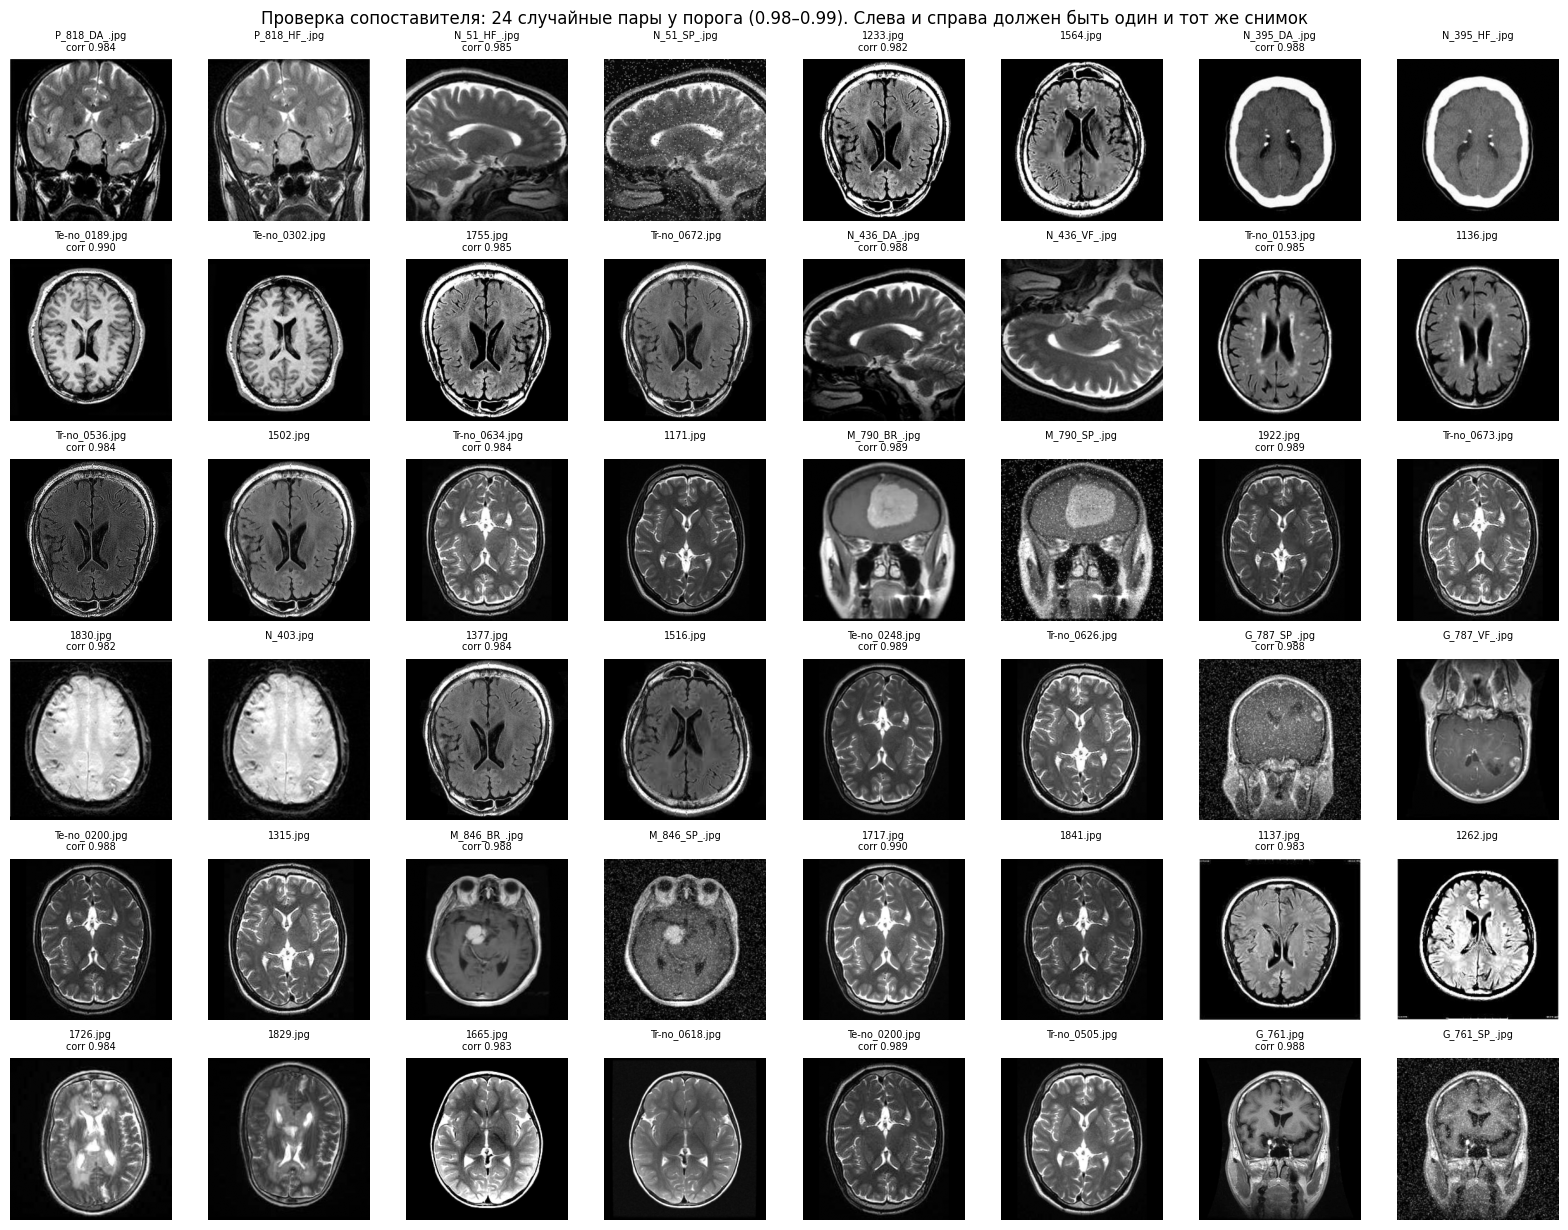


Состав классов по типу файлов (все данные):
label            Глиома  Менингиома  Гипофиз  Опухоли нет
source                                                   
Br35H/прочие          0           0        0           47
Kaggle Tr/Te        942         943     1011          652
P/G/M/N_n           187          87      120           63
SARTAJ-подобные     323         278      254           52
аугм. копии        1060         549      661          408
числовые            335         204      351          623

ТОЛЬКО новые пациенты Figshare (точно пациент-независимо, 3 класса): {'accuracy': 0.893, 'balanced_acc': 0.904, 'macro_f1': 0.674, 'tumor_sens': 0.994, 'tumor_spec': 0.0} n = 990
Остальные тест-снимки: {'accuracy': 0.852, 'balanced_acc': 0.76, 'macro_f1': 0.771, 'tumor_sens': 0.928, 'tumor_spec': 0.973, 'tumor_auc': 0.98} n = 582

Опухоль/норма ВНУТРИ одного типа файлов (где есть оба класса):
  Kaggle Tr/Te: n=630  AUC 0.996  чувств. 0.994  спец. 0.942
  P/G/M/N_n: n=72  AUC 1.000  чув

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Закрашивание опухоли [Figshare, новые пациенты]: «опухоль» до 99.3% -> после 98.9%
Закрашивание опухоли [Снимки организаторов (тест)]: «опухоль» до 99.4% -> после 98.3%


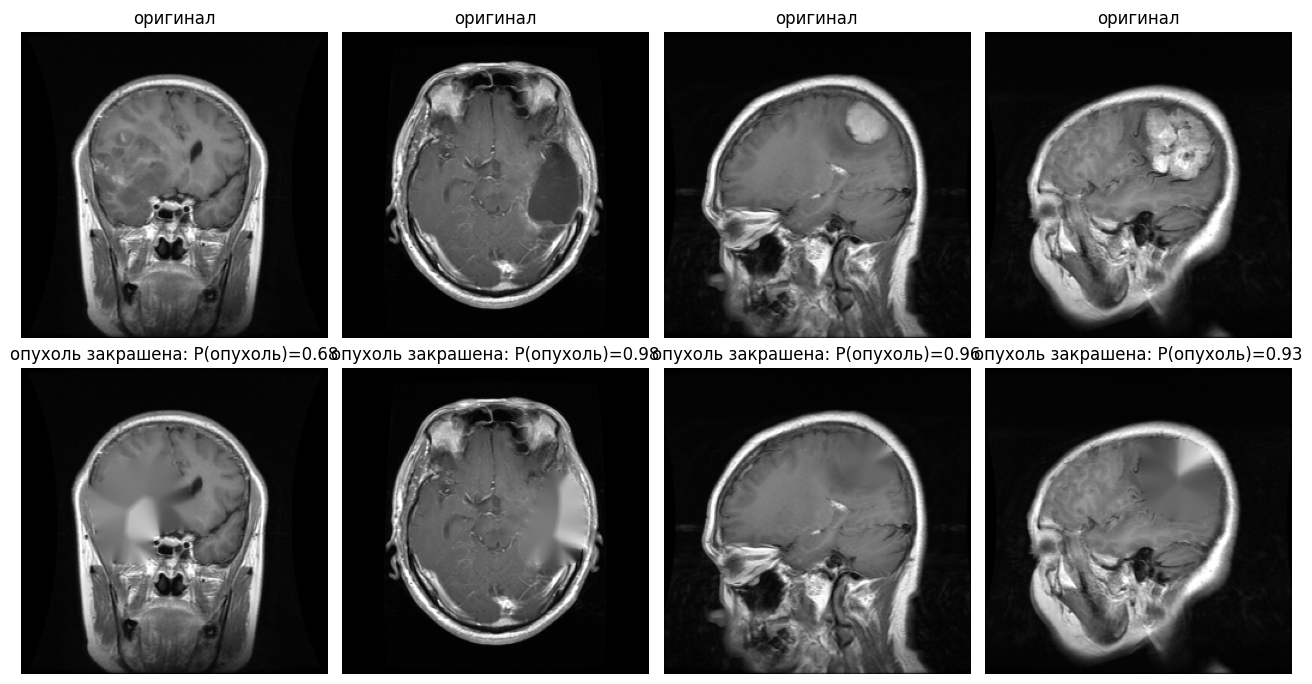

Наивная модель на официальном тесте: {'all': 0.9588455371459113, 'with_copy': 0.9751381215469613, 'n_with_copy': 1448, 'without_copy': 0.9030732860520094, 'n_without_copy': 423}
Здоровые тест-снимки, где демо нарисует хоть какой-то контур: 0.3% из 332

Сохранено: review_checks_v3.json, figs/matcher_check.png, figs/inpaint_test.png


In [48]:
# === 14. ПРОВЕРКИ ПО ЗАМЕЧАНИЯМ НЕЗАВИСИМОГО РЕЦЕНЗЕНТА ===
import datetime
R14 = {}
for f in ['split_v3.csv', 'ckpt/cls_v3_best.pt', 'ckpt/seg_v3_best.pt', 'ckpt/cls_naive_v3_best.pt']:
    p_ = W/f; print(f, datetime.datetime.fromtimestamp(p_.stat().st_mtime).strftime('%d.%m %H:%M') if p_.exists() else 'НЕТ ФАЙЛА')
g_fresh, _ = build(THR, THR, True, True)
ov = {f'{a_}-{b_}': len(set(g_fresh[df.part == a_]) & set(g_fresh[df.part == b_])) for a_, b_ in [('train', 'val'), ('train', 'test'), ('val', 'test')]}
print('Пересечения групп (пересчитанных заново) между частями:', ov, '-> должно быть 0'); R14['fresh_group_overlap'] = ov
null_fp = int((fbest[LAB == 3] >= .98).sum()); xcls = int(((C >= .98) & (LAB[I] != LAB[J])).sum())
print(f'Нулевой тест: совпадений Figshare (там только опухоли) со снимками «нет опухоли» при >=0.98: {null_fp} из {(LAB == 3).sum()}')
print(f'Пар-«копий» (>=0.98) с разными метками: {xcls}')
R14.update(null_test_figshare_vs_normal=null_fp, cross_label_pairs=xcls)
Zc = zt(S64).to(dev); Zd = [zt(d8_t(S64, t)).to(dev) for t in range(8)]
def nn_search(test_idx, train_idx):
    train_idx = np.asarray(train_idx); T = Zc[torch.as_tensor(train_idx, device=dev)]; vs, ar = [], []
    for s in range(0, len(test_idx), 512):
        q = torch.as_tensor(np.asarray(test_idx[s:s+512]), device=dev)
        c = torch.stack([Zd[t][q] @ T.T for t in range(8)]).max(0).values; v, a = c.max(1)
        vs.append(v.cpu().numpy()); ar.append(a.cpu().numpy())
    return np.concatenate(vs), train_idx[np.concatenate(ar)]
off_te, off_tr = np.where(te)[0], np.where(~te)[0]
nnv_off, nni_off = nn_search(off_te, off_tr); nnv_our, nni_our = nn_search(TE, TR)
del Zc, Zd; torch.cuda.empty_cache()
R14['direct_copy_share'] = {'official': float((nnv_off >= .98).mean()), 'ours': float((nnv_our >= .98).mean())}
print('Прямая доля тест-снимков с копией в обучении (ближайший сосед >=0.98):', R14['direct_copy_share'])
R14['one_nn_accuracy'] = {'official': float((LAB[nni_off] == LAB[off_te]).mean()), 'ours': float((LAB[nni_our] == LAB[TE]).mean())}
print('«Подсмотреть ответ у ближайшего снимка обучения» (1-NN, без нейросети):', R14['one_nn_accuracy'])
band = np.where((C >= .98) & (C < .99))[0]; pk = np.random.RandomState(5).choice(band, min(24, len(band)), replace=False)
fig, ax = plt.subplots(6, 8, figsize=(16, 12.5), squeeze=False)
for k, q in enumerate(pk):
    r, c2 = divmod(k, 4)
    for d, ii in enumerate([I[q], J[q]]):
        a_ = ax[r, c2*2+d]; a_.imshow(A[ii], cmap='gray'); a_.axis('off'); a_.set_title(f'{df.name[ii][:14]}' + (f'\ncorr {C[q]:.3f}' if d == 0 else '\n'), fontsize=7)
for a_ in ax.flat: a_.axis('off')
plt.suptitle('Проверка сопоставителя: 24 случайные пары у порога (0.98–0.99). Слева и справа должен быть один и тот же снимок'); plt.tight_layout()
plt.savefig(W/'figs'/'matcher_check.png', dpi=110); plt.show()
print('\nСостав классов по типу файлов (все данные):'); print(pd.crosstab(df.source, df.label).rename(columns=dict(enumerate(CLASSES))))
fp_ = df.pid.values[TE] != ''
R14['patient_independent_subset'] = evaluate(Pte[fp_], LAB[TE][fp_]); R14['other_subset'] = evaluate(Pte[~fp_], LAB[TE][~fp_])
print('\nТОЛЬКО новые пациенты Figshare (точно пациент-независимо, 3 класса):', {k: round(v, 3) for k, v in R14['patient_independent_subset'].items() if isinstance(v, float)}, 'n =', fp_.sum())
print('Остальные тест-снимки:', {k: round(v, 3) for k, v in R14['other_subset'].items() if isinstance(v, float)}, 'n =', (~fp_).sum())
t2 = df.iloc[TE].copy(); t2['tum'] = LAB[TE] != 3; t2['p'] = 1 - Pte[:, 3]; t2['ok'] = Pte.argmax(1) == LAB[TE]
print('\nОпухоль/норма ВНУТРИ одного типа файлов (где есть оба класса):'); R14['within_source'] = {}
for s_, g_ in t2.groupby('source'):
    if g_.tum.nunique() == 2:
        auc_ = roc_auc_score(g_.tum, g_.p); spec_ = ((g_.p < .5) & ~g_.tum).sum() / (~g_.tum).sum(); sens_ = ((g_.p >= .5) & g_.tum).sum() / g_.tum.sum()
        R14['within_source'][s_] = dict(n=len(g_), auc=float(auc_), sens=float(sens_), spec=float(spec_))
        print(f'  {s_}: n={len(g_)}  AUC {auc_:.3f}  чувств. {sens_:.3f}  спец. {spec_:.3f}')
t2['nn'] = pd.cut(nnv_our, [0, .85, .9, .93, .95, .98, 1.01])
print('\nТочность в зависимости от похожести на обучение (растёт сильно -> остаточная утечка):')
print(t2.groupby('nn', observed=True).ok.agg(['mean', 'size']).round(3))
@torch.no_grad()
def cls_arr(m, X):
    m.eval(); out = []
    for s in range(0, len(X), 128):
        x = torch.tensor((X[s:s+128].astype(np.float32) - MEAN) / STD)[:, None].repeat(1, 3, 1, 1).to(dev)
        with torch.autocast('cuda'):
            p = m(x).float().softmax(1) + m(torch.flip(x, (3,))).float().softmax(1)
        out.append((p / 2).cpu().numpy())
    return np.concatenate(out)
def inpaint_all(X_, M_): return np.stack([cv2.inpaint(X_[k], cv2.dilate(M_[k].astype(np.uint8), np.ones((9, 9), np.uint8)), 5, cv2.INPAINT_TELEA) for k in range(len(X_))])
R14['inpaint'] = {}
for nm, X_, M_ in [('Figshare, новые пациенты', XF, MF)] + ([('Снимки организаторов (тест)', XO, MO)] if q_te else []):
    p0, p1 = cls_arr(model, X_), cls_arr(model, inpaint_all(X_, M_))
    R14['inpaint'][nm] = dict(n=len(X_), tumor_before=float((p0.argmax(1) != 3).mean()), tumor_after=float((p1.argmax(1) != 3).mean()),
                             mean_p_tumor_before=float((1 - p0[:, 3]).mean()), mean_p_tumor_after=float((1 - p1[:, 3]).mean()))
    print(f'Закрашивание опухоли [{nm}]: «опухоль» до {R14["inpaint"][nm]["tumor_before"]:.1%} -> после {R14["inpaint"][nm]["tumor_after"]:.1%}')
k_show = np.random.RandomState(2).choice(len(XF), 4, replace=False); Xi = inpaint_all(XF[k_show], MF[k_show]); pi_ = cls_arr(model, Xi)
fig, ax = plt.subplots(2, 4, figsize=(13, 7), squeeze=False)
for c2, k in enumerate(k_show):
    ax[0, c2].imshow(XF[k], cmap='gray'); ax[0, c2].set_title('оригинал'); ax[1, c2].imshow(Xi[c2], cmap='gray')
    ax[1, c2].set_title(f'опухоль закрашена: P(опухоль)={1 - pi_[c2, 3]:.2f}')
for a_ in ax.flat: a_.axis('off')
plt.tight_layout(); plt.savefig(W/'figs'/'inpaint_test.png', dpi=120); plt.show()
naive = timm.create_model('efficientnet_b0', pretrained=False, num_classes=4).to(dev)
naive.load_state_dict(torch.load(W/'ckpt'/'cls_naive_v3_best.pt', map_location=dev))
Pn = cls_predict(naive, off_te); okn = Pn.argmax(1) == LAB[off_te]; cp_ = nnv_off >= .98
R14['naive_official'] = dict(all=float(okn.mean()), with_copy=float(okn[cp_].mean()), n_with_copy=int(cp_.sum()),
                            without_copy=float(okn[~cp_].mean()) if (~cp_).any() else None, n_without_copy=int((~cp_).sum()))
print('Наивная модель на официальном тесте:', R14['naive_official'])
del naive; torch.cuda.empty_cache()
def clean(pm, a=30):
    out = []
    for p_ in pm:
        m_ = p_.astype(np.uint8); k_, l_, st_, _ = cv2.connectedComponentsWithStats(m_)
        for c_ in range(1, k_):
            if st_[c_, cv2.CC_STAT_AREA] < a: m_[l_ == c_] = 0
        out.append(m_)
    return np.stack(out)
if nt:
    pn = seg_probs(A[nt]) > .5
    R14['healthy_any_contour_rate'] = float((clean(pn).sum((1, 2)) > 0).mean())
    print(f'Здоровые тест-снимки, где демо нарисует хоть какой-то контур: {R14["healthy_any_contour_rate"]:.1%} из {len(nt)}')
json.dump(R14, open(W/'review_checks_v3.json', 'w'), ensure_ascii=False, indent=1, default=str)
print('\nСохранено: review_checks_v3.json, figs/matcher_check.png, figs/inpaint_test.png')

[Figshare, новые пациенты] контур сегментации: до 96.3% -> после закрашивания 82.7%;  «классификатор И контур»: до 95.5% -> после 82.0%
[Снимки организаторов (тест)] контур сегментации: до 98.1% -> после закрашивания 82.5%;  «классификатор И контур»: до 97.6% -> после 81.6%

Честный тест: правило решения «есть опухоль»
  только классификатор: чувствительность 0.982, специфичность 0.973
  только сегментация: чувствительность 0.939, специфичность 0.997
  классификатор И сегментация: чувствительность 0.932, специфичность 0.997


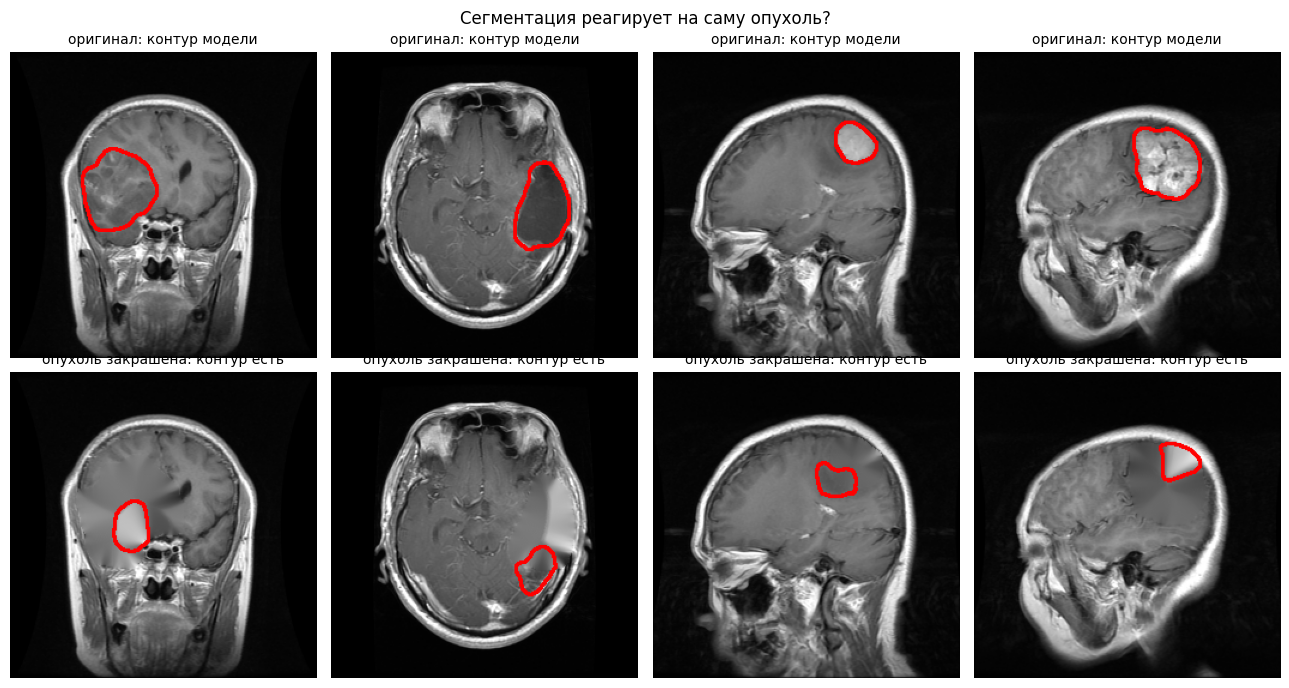

In [49]:
# === 15. СЕГМЕНТАЦИЯ ПОСЛЕ ЗАКРАШИВАНИЯ + ДЕТЕКЦИЯ «С ПОДТВЕРЖДЕНИЕМ ОБЛАСТЬЮ» ===
R15 = {}
def area(pm): return clean(pm > .5).sum((1, 2))
for nm, X_, M_ in [('Figshare, новые пациенты', XF, MF)] + ([('Снимки организаторов (тест)', XO, MO)] if q_te else []):
    Xi_ = inpaint_all(X_, M_)
    a0, a1 = area(seg_probs(X_)), area(seg_probs(Xi_))
    p0, p1 = cls_arr(model, X_), cls_arr(model, Xi_)
    R15[nm] = dict(n=len(X_), contour_before=float((a0 > 0).mean()), contour_after=float((a1 > 0).mean()),
                   both_before=float((((1 - p0[:, 3]) >= .5) & (a0 > 0)).mean()), both_after=float((((1 - p1[:, 3]) >= .5) & (a1 > 0)).mean()))
    print(f'[{nm}] контур сегментации: до {R15[nm]["contour_before"]:.1%} -> после закрашивания {R15[nm]["contour_after"]:.1%};'
          f'  «классификатор И контур»: до {R15[nm]["both_before"]:.1%} -> после {R15[nm]["both_after"]:.1%}')
aT = area(seg_probs(A[TE])); pt_ = 1 - Pte[:, 3]; tt_ = LAB[TE] != 3; fp_ = df.pid.values[TE] != ''
print('\nЧестный тест: правило решения «есть опухоль»')
for rule, fl in [('только классификатор', pt_ >= .5), ('только сегментация', aT > 0), ('классификатор И сегментация', (pt_ >= .5) & (aT > 0))]:
    R15['test: ' + rule] = dict(sens=float((fl & tt_).sum() / tt_.sum()), spec=float((~fl & ~tt_).sum() / (~tt_).sum()))
    print(f'  {rule}: чувствительность {R15["test: " + rule]["sens"]:.3f}, специфичность {R15["test: " + rule]["spec"]:.3f}')
ks = np.random.RandomState(2).choice(len(XF), 4, replace=False); Xi4 = inpaint_all(XF[ks], MF[ks])
pm0, pm1 = seg_probs(XF[ks]) > .5, seg_probs(Xi4) > .5
fig, ax = plt.subplots(2, 4, figsize=(13, 7), squeeze=False)
for c2 in range(4):
    for r, (img, pm) in enumerate([(XF[ks[c2]], pm0[c2]), (Xi4[c2], pm1[c2])]):
        rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB); cs, _ = cv2.findContours(clean(pm[None])[0], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(rgb, cs, -1, (255, 0, 0), 2); ax[r, c2].imshow(rgb); ax[r, c2].axis('off')
        ax[r, c2].set_title('оригинал: контур модели' if r == 0 else ('опухоль закрашена: контура нет' if not pm.any() else 'опухоль закрашена: контур есть'), fontsize=10)
plt.suptitle('Сегментация реагирует на саму опухоль?'); plt.tight_layout(); plt.savefig(W/'figs'/'inpaint_seg.png', dpi=120); plt.show()
json.dump(R15, open(W/'inpaint_seg_v3.json', 'w'), ensure_ascii=False, indent=1)